In [ ]:
%pip install datasets google-cloud-aiplatform pandas pillow scikit-learn emoji tqdm bert-score torch transformers

  Using cached bert_score-0.3.13-py3-none-any.whl.metadata (15 kB)
  Using cached torch-2.9.1-cp312-none-macosx_11_0_arm64.whl.metadata (30 kB)
  Using cached transformers-4.57.3-py3-none-any.whl.metadata (43 kB)
  Using cached setuptools-80.9.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached huggingface_hub-0.36.0-py3-none-any.whl.metadata (14 kB)
  Using cached regex-2025.11.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (40 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-macosx_11_0_arm64.whl.metadata (7.3 kB)
  Using cached safetensors-0.7.0-cp38-abi3-macosx_11_0_arm64.whl.metadata (4.1 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached bert_score-0.3.13-py3-none-any.whl (61 kB)
   ━━╸

In [ ]:
import json
import time
import pandas as pd
import vertexai
from vertexai.generative_models import GenerativeModel, Part, HarmCategory, HarmBlockThreshold
from io import BytesIO
from sklearn.metrics import f1_score, accuracy_score
from tqdm import tqdm
from PIL import Image

# --- CONFIGURATION --- 
PROJECT_ID = "endless-upgrade-479607-r4"  
LOCATION = "europe-west1"
MODEL_NAME = "gemini-2.5-flash"

# Constants from vertex.ts
INTEREST_TAGS = [
  "Technology", "Sports", "Music", "Art", "Travel", "Food", "Fashion", 
  "Photography", "Gaming", "Fitness", "Books", "Movies", "Science", 
  "Business", "Education", "Health", "Nature", "Pets", "Lifestyle", 
  "Relationships", "Mental Health", "Career", "Finance", "News", 
  "Culture", "Self Improvement", "Entertainment", "Internet Culture",
]

VALID_HARMFUL_TYPES = [
  "VIOLENCE", "HATE_SPEECH", "NUDITY", "SPAM", "HARASSMENT", "SELF_HARM",
  "SUICIDE", "DESPAIR", "MISINFORMATION", "DANGEROUS_BEHAVIOR",
  "PSYCHOLOGICAL_HARM", "MANIPULATION", "COMMUNITY_HARM", "OTHER",
]

def init_vertex(): 
    vertexai.init(project=PROJECT_ID, location=LOCATION)
    print(f"Vertex AI initialized for project: {PROJECT_ID}")
    return True

In [93]:
def analyze_post_with_gemini(text, image_pil): 
    model = GenerativeModel(MODEL_NAME)
    
    # PROMPT V10: BACK TO NEUTRAL DOMINANCE
    # Strategy: Dataset logic seems to be:
    # - "Political Attacks/Sarcasm/Bad News for Others" -> NEUTRAL (Not Negative, Not Positive).
    # - "Routine Campaigning/Events" -> NEUTRAL (unless extremely explicitly happy).
    # - "Positive" -> Reserved for explicit promises, hope, or direct praise.
    # - "Negative" -> Reserved for tragedy/humanitarian crisis only.
    
    prompt_text = f"""Analyze the social media post (Text + Image) acting as an MVSA dataset annotator.
    
    RULES FOR SENTIMENT:

    1. **POSITIVE (Explicit Hope/Praise):**
       - **Promises/Goals:** "I will help", "Change this country", "Plan for future".
       - **Praise/Gratitude:** "Honoured to serve", "Best leader", "Thank you".
       - **High Emotion:** "So excited!", "Wonderful turnout!". (Must be stronger than just "Getting ready").

    2. **NEUTRAL (Politics as Usual - THE DEFAULT):**
       - **Criticism/Sarcasm:** "Record is skipping", "Tired of hearing", "Stop Harper", "Kick them out". (Attacks are Neutral).
       - **Rival Failure:** "Bad news for NDP", "Conservatives sinking". (Reporting on failure is Neutral).
       - **Routine Campaigning:** "Getting ready", "Leaders debate tonight", "Door knocking", "On the bus". (Just doing the job).
       - **Facts/Polls:** "Latest numbers show...", "Election is today".

    3. **NEGATIVE (Humanitarian Crisis Only):**
       - **Tragedy/Suffering:** "Refugee crisis", "War", "Death", "Bodies on beach".
       - **Despair:** "Heartbroken", "Devastated" (Personal emotional pain, not political anger).
       - **Hate Speech:** Slurs, threats of violence.

    JSON OUTPUT FORMAT:
    {{
      "reasoning": "Explain classification based on the strict NEUTRAL dominance for politics.",
      "sentimentScore": number (0.0=Neg, 0.5=Neu, 1.0=Pos),
      "emotion": "POSITIVE" | "NEGATIVE" | "NEUTRAL"
    }}
    """
    
    parts = [prompt_text]
    if text:
        parts.append(f"\n\nPost caption: {text}")
    
    if image_pil:
        img_byte_arr = BytesIO()
        image_pil.save(img_byte_arr, format=image_pil.format if image_pil.format else 'JPEG')
        img_bytes = img_byte_arr.getvalue()
        parts.append(Part.from_data(img_bytes, mime_type="image/jpeg"))

    generation_config = {
        "temperature": 0.0,
        "response_mime_type": "application/json"
    }
    
    safety_settings = {
        HarmCategory.HARM_CATEGORY_HARASSMENT: HarmBlockThreshold.BLOCK_NONE,
        HarmCategory.HARM_CATEGORY_HATE_SPEECH: HarmBlockThreshold.BLOCK_NONE,
        HarmCategory.HARM_CATEGORY_SEXUALLY_EXPLICIT: HarmBlockThreshold.BLOCK_NONE,
        HarmCategory.HARM_CATEGORY_DANGEROUS_CONTENT: HarmBlockThreshold.BLOCK_NONE,
    }

    try:
        response = model.generate_content(
            parts,
            generation_config=generation_config,
            safety_settings=safety_settings
        )
        return json.loads(response.text)
    except Exception as e:
        print(f"gemini error: {e}")
        return None

Loading local MVSA dataset from MVSA/data...
Found 19600 entries in label file.


Loading local MVSA dataset from MVSA/data...
Found 19600 entries in label file.


100%|██████████| 19600/19600 [00:01<00:00, 12394.17it/s]

Loading local MVSA dataset from MVSA/data...
Found 19600 entries in label file.


100%|██████████| 19600/19600 [00:01<00:00, 12394.17it/s]

Skipped 1194 ambiguous samples (no clear majority).
Loaded 18406 valid samples locally.
First sample:
{'id': '2499', 'text': 'Knocked doors with the venerable #TeamTrudeau #lpc candidate @kylejpeterson this aft in my hometown, Aurora! #elxn42', 'image_path': 'MVSA/data/2499.jpg', 'label': 'POSITIVE'}


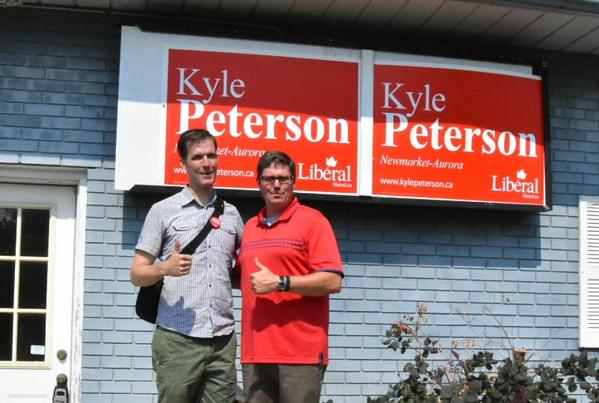

In [94]:
# Load Data Locally from MVSA folder
import os

DATA_DIR = "MVSA/data"
LABEL_FILE = "MVSA/labelResultAll.txt"

def get_majority_label(labels):
    # simplistic majority vote
    counts = {
        "positive": 0,
        "negative": 0,
        "neutral": 0
    }
    for l in labels:
        l = l.strip().lower()
        if l in counts:
            counts[l] += 1
    
    # Check for strict majority (>= 2 votes out of 3)
    sorted_counts = sorted(counts.items(), key=lambda item: item[1], reverse=True)
    
    top_label, top_count = sorted_counts[0]
    
    # If the top count is < 2, it implies a 1-1-1 tie (or 0-0-0)
    # Return None to signal ambiguous ground truth
    if top_count < 2:
        return None
        
    return top_label.upper()

def load_local_mvsa():
    print(f"Loading local MVSA dataset from {DATA_DIR}...")
    items = []
    
    if not os.path.exists(LABEL_FILE):
        print(f"Error: Label file not found at {LABEL_FILE}")
        return []

    with open(LABEL_FILE, 'r', encoding='utf-8', errors='replace') as f:
        lines = f.readlines()
    
    # Skip header
    data_lines = lines[1:]
    print(f"Found {len(data_lines)} entries in label file.")
    
    skipped_count = 0
    for line in tqdm(data_lines):
        parts = line.strip().split() # split by whitespace
        if len(parts) < 4: continue
        
        pid = parts[0]
        
        # Ground Truth Strategy: Text Majority Vote
        text_labels = []
        try:
            for p in parts[1:]:
                # Each part is "text_sentiment,image_sentiment"
                if ',' in p:
                    text_labels.append(p.split(',')[0])
            
            if not text_labels:
                gt_label = None
            else:
                gt_label = get_majority_label(text_labels)
        except:
            gt_label = None

        # Filter out ambiguous samples
        if gt_label is None:
            skipped_count += 1
            continue

        # Load Text
        txt_path = os.path.join(DATA_DIR, f"{pid}.txt")
        text_content = ""
        if os.path.exists(txt_path):
            try:
                with open(txt_path, 'r', encoding='utf-8', errors='replace') as tf:
                    text_content = tf.read().strip()
            except UnicodeDecodeError:
                with open(txt_path, 'r', encoding='latin-1', errors='replace') as tf:
                    text_content = tf.read().strip()

        # Check Image Path
        img_path = os.path.join(DATA_DIR, f"{pid}.jpg")
        if not os.path.exists(img_path): 
            continue
              
        items.append({
            "id": pid,
            "text": text_content,
            "image_path": img_path,
            "label": gt_label
        })
    
    print(f"Skipped {skipped_count} ambiguous samples (no clear majority).")
    return items

dataset = load_local_mvsa()
print(f"Loaded {len(dataset)} valid samples locally.")

# Preview first item
if len(dataset) > 0:
    sample = dataset[0]
    print("First sample:")
    print(sample)
    try:
        display(Image.open(sample['image_path']))
    except Exception as e:
        print(f"Could not display image: {e}")
else:
    print("No data found! Check paths.")

In [95]:
# Run Evaluation on a subset (1000 to 1050)
if not init_vertex():
    raise ValueError("Please set PROJECT_ID first")

# Change range as requested
START_IDX = 1000
NUM_SAMPLES = 10
subset = dataset[START_IDX : START_IDX + NUM_SAMPLES]

results = []

print(f"Analyzing {len(subset)} samples (Index {START_IDX} to {START_IDX+NUM_SAMPLES})...")
for i, item in enumerate(tqdm(subset)):
    text = item.get('text', '')
    img_path = item.get('image_path', None)
    label_raw = item.get('label', None)
    pid = item.get('id')
    
    image = None
    if img_path and os.path.exists(img_path):
        try:
            image = Image.open(img_path)
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")

    # Call Gemini
    prediction = analyze_post_with_gemini(text, image)
    
    res_entry = {
        "idx": START_IDX + i,
        "id": pid,
        "text_snippet": text[:50] if text else "",
        "ground_truth_raw": label_raw,
        "predicted_full": prediction
    }
    
    if prediction:
        res_entry["predicted_emotion"] = prediction.get("emotion")
        res_entry["sentiment_score"] = prediction.get("sentimentScore")
        res_entry["reasoning"] = prediction.get("reasoning") # Store reasoning for debugging
    
    results.append(res_entry)
    time.sleep(1) # Rate limiting

df = pd.DataFrame(results)
print("Analysis Finished.")
df.head()

Vertex AI initialized for project: endless-upgrade-479607-r4
Analyzing 10 samples (Index 1000 to 1010)...


Vertex AI initialized for project: endless-upgrade-479607-r4
Analyzing 10 samples (Index 1000 to 1010)...


  0%|          | 0/10 [00:00<?, ?it/s]/Users/10vancauhoivisao/Documents/GitHub/social-media-app-FE/.venv/lib/python3.12/site-packages/vertexai/generative_models/_generative_models.py:433: UserWarning: This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.
  warning_logs.show_deprecation_warning()
100%|██████████| 10/10 [01:18<00:00,  7.85s/it]

Vertex AI initialized for project: endless-upgrade-479607-r4
Analyzing 10 samples (Index 1000 to 1010)...


  0%|          | 0/10 [00:00<?, ?it/s]/Users/10vancauhoivisao/Documents/GitHub/social-media-app-FE/.venv/lib/python3.12/site-packages/vertexai/generative_models/_generative_models.py:433: UserWarning: This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.
  warning_logs.show_deprecation_warning()
100%|██████████| 10/10 [01:18<00:00,  7.85s/it]

Analysis Finished.


,idx,id,text_snippet,ground_truth_raw,predicted_full,predicted_emotion,sentiment_score,reasoning
0,1000,3645,#LPC government under @JustinTrudeau will help Sou,POSITIVE,"{'reasoning': 'The post states that the '#LPC government under @JustinTrudeau will help Southern Alberta make investments in flood mitigation'. According to the rules, 'Promises/Goals' such as 'I will help' or 'Plan for future' are classified as POSITIVE. This statement is a clear promise of future action to provide assistance.', 'sentimentScore': 1.0, 'emotion': 'POSITIVE'}",POSITIVE,1.0,"The post states that the '#LPC government under @JustinTrudeau will help Southern Alberta make investments in flood mitigation'. According to the rules, 'Promises/Goals' such as 'I will help' or 'Plan for future' are classified as POSITIVE. This statement is a clear promise of future action to provide assistance."
1,1001,3646,#BCwine focus of @pmharper @LaureenHarper stop tod,NEUTRAL,"{'reasoning': 'The post describes a routine campaign stop by the Prime Minister and his wife at a winery during an election (#elxn42). This falls under the 'Routine Campaigning' rule ('Just doing the job'), which is explicitly classified as NEUTRAL. The image visually confirms this factual reporting of a campaign event, without conveying any explicit hope, praise, high emotion, or humanitarian crisis.', 'sentimentScore': 0.5, 'emotion': 'NEUTRAL'}",NEUTRAL,0.5,"The post describes a routine campaign stop by the Prime Minister and his wife at a winery during an election (#elxn42). This falls under the 'Routine Campaigning' rule ('Just doing the job'), which is explicitly classified as NEUTRAL. The image visually confirms this factual reporting of a campaign event, without conveying any explicit hope, praise, high emotion, or humanitarian crisis."
2,1002,3647,.@Dantheeditor column: Conservatives sinking in de,POSITIVE,"{'reasoning': 'The post's text, 'Conservatives sinking in denial during Duffy trial,' constitutes criticism of a political party and reports on their perceived failure. According to the rules, 'Criticism/Sarcasm' and 'Rival Failure' are classified as NEUTRAL. The image depicts a politician interacting with people, which is typical political activity and does not override the explicit neutral classification of the text.', 'sentimentScore': 0.5, 'emotion': 'NEUTRAL'}",NEUTRAL,0.5,"The post's text, 'Conservatives sinking in denial during Duffy trial,' constitutes criticism of a political party and reports on their perceived failure. According to the rules, 'Criticism/Sarcasm' and 'Rival Failure' are classified as NEUTRAL. The image depicts a politician interacting with people, which is typical political activity and does not override the explicit neutral classification of the text."
3,1003,3648,Another leaders' debate tonight in Calgary - the e,POSITIVE,"{'reasoning': 'The post describes a routine political event ('Another leaders' debate tonight') which falls under 'Routine Campaigning' and is classified as NEUTRAL. It also mentions 'the epicentre of oil bust', which describes a factual economic situation. According to the rules, 'Facts/Polls' are NEUTRAL. The term 'oil bust' describes an economic downturn, but it does not constitute a 'Humanitarian Crisis Only' (Tragedy/Suffering, Despair, Hate Speech) to warrant a NEGATIVE classification. Therefore, the overall sentiment is NEUTRAL.', 'sentimentScore': 0.5, 'emotion': 'NEUTRAL'}",NEUTRAL,0.5,"The post describes a routine political event ('Another leaders' debate tonight') which falls under 'Routine Campaigning' and is classified as NEUTRAL. It also mentions 'the epicentre of oil bust', which describes a factual economic situation. According to the rules, 'Facts/Polls' are NEUTRAL. The term 'oil bust' describes an economic downturn, but it does not constitute a 'Humanitarian Crisis Only' (Tragedy/Suffering, Despair, Hate Speech) to warrant a NEGATIVE classification. Therefore, the overall sentiment is NEUTRAL."
4,1004,3649,.@kenthehr

In [91]:
print(df)

    idx    id                                        text_snippet ground_truth_raw                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           predicted_full predicted_emotion  sentiment_score  \
0  1000  3645  #LPC government under @JustinTrudeau will help Sou         POSITIVE                                                                                                    

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from bert_score import score

# Metrics Calculation using BERTScore
def normalize_gt(val):
    s = str(val).lower().strip()
    if s in ['positive', 'joy', '1']: return "POSITIVE"
    if s in ['negative', 'sadness', 'anger', 'fear', 'disgust', '2']: return "NEGATIVE"
    return "NEUTRAL"

def normalize_pred(val):
    if not val: return "NEUTRAL"
    s = str(val).upper().strip()
    return s if s in ['POSITIVE', 'NEGATIVE', 'NEUTRAL'] else "NEUTRAL"

df['y_true'] = df['ground_truth_raw'].apply(normalize_gt)
df['y_pred'] = df['predicted_emotion'].apply(normalize_pred)

print(f"\n=== Calculating BERTScore (N={len(df)}) ===")

cands = df['y_pred'].tolist()
refs = df['y_true'].tolist()

# Calculate BERTScore 
# lang="en" uses roberta-large by default which gives better semantic comparison than exact match
P, R, F1 = score(cands, refs, lang="en", verbose=True)

print(f"\n=== BERTScore Results ===")
print(f"Precision (Mean): {P.mean():.4f}")
print(f"Recall (Mean):    {R.mean():.4f}")
print(f"F1 Score (Mean):  {F1.mean():.4f}")

# Visualization
plt.figure(figsize=(8, 6))
sns.histplot(F1.numpy(), bins=20, kde=True)
plt.title('Distribution of BERTScore F1')
plt.xlabel('BERTScore F1')
plt.show()


=== Evaluation Metrics ===
Accuracy:       0.8000

Example Mismatches:
                                         text_snippet    y_true   y_pred  sentiment_score
2  .@Dantheeditor column: Conservatives sinking in de  POSITIVE  NEUTRAL              0.5
3  Another leaders' debate tonight in Calgary - the e  POSITIVE  NEUTRAL              0.5
